# Chapter 3 · Vimentin–Microtubule Bonds — Noisy Forces and Experimental Design

Sections 3.4–3.5 (pp. 45–51), Figures 14–16.

| Figure | Page | Content |
|---|---|---|
| Figure 14 | p. 46 | Likelihood of a noisy force measurement |
| Figure 15 | p. 49 | Influence of the driving velocity on the posterior |
| Figure 16 | p. 50 | Expected information gain vs. driving velocity |

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import sympy as sp
from scipy.ndimage import gaussian_filter
from scipy.stats import binned_statistic

import lambert_thesis as lt
from lambert_thesis import bonds, plotting
from lambert_thesis.plotting import savefig

plotting.setup()
rng = lt.set_seed(lt.SEED)

RU0_GT, XU_GT = 0.05, 0.2
DT = 1e-2
force = bonds.force_curve(50)

## 3.4 Noisy force measurements

Only the force on the beads is measured; it propagates through the thermally fluctuating polymer before acting on
the bond, and the measurement itself is noisy. The unbinding is now controlled by the **latent** force $f$ at the bond,
while the measured force $F$ is related to it by a Gaussian perturbation $p(F\mid f)=\mathcal N(F\mid f,\sigma^2)$.
The likelihood of a measured $F$ is obtained by marginalising the latent force:

$$L(F_i,\bar s_i\mid r_{u,0},x_u)=\int_{-\infty}^{\infty}L(f_i,\bar s_i\mid r_{u,0},x_u)\,\mathcal N(F\mid f,\sigma^2)\,\mathrm df .$$

Assuming at most one event per $\Delta t$, the outer exponential is linearised, $L\approx\Delta t\,r_{u,0}e^{f x_u}$
($k_BT=1$), and the integral can be done in closed form. We let `sympy` do it, with the Gaussian kernel written as
$\frac1\sigma e^{-(F-f)^2/\sigma^2}$:

In [2]:
r, x, s, F, f, dt = sp.symbols("r_{u0} x_u sigma F f Delta_t", real=True)
s = sp.Symbol("sigma", positive=True)
kernel = 1 / s * sp.exp(-(F - f) ** 2 / s**2)

L_original = sp.simplify(sp.integrate(dt * r * sp.exp(f * x) * kernel, (f, -sp.oo, sp.oo)))
L_original

sqrt(pi)*Delta_t*r_{u0}*exp(x_u*(F + sigma**2*x_u/4))

The correction $\sigma^2x_u/4$ is small: in this model, negative latent forces *lower* the unbinding rate below
$r_{u,0}$, so positive and negative excursions almost compensate. If the bond only reacts to the **absolute value**
of the force, the integral becomes

In [3]:
L_absolute = sp.simplify(sp.integrate(dt * r * sp.exp(sp.Abs(f) * x) * kernel, (f, -sp.oo, sp.oo)))
L_absolute

sqrt(pi)*Delta_t*r_{u0}*(exp(2*F*x_u)*erf((2*F + sigma**2*x_u)/(2*sigma)) + exp(2*F*x_u) - erf((2*F - sigma**2*x_u)/(2*sigma)) + 1)*exp(x_u*(-F + sigma**2*x_u/4))/2

Now the measurement noise strongly affects the likelihood (Figure 14). We plot both models as functions of the observed
force, in units of $\sqrt\pi\,\Delta t\,r_{u,0}$, for $x_u=0.5$. Without noise ($\sigma\to0$) the latent force equals the
observed one and the models are simply $e^{x_uF}$ and $e^{x_u|F|}$.

In [4]:
xu_val = 0.5
Fs = np.linspace(-2.7, 2.7, 400)
norm = {dt: 1, r: 1 / sp.sqrt(sp.pi)}
lam = lambda expr, sigma: sp.lambdify(F, expr.subs(norm).subs({x: xu_val, s: sigma}), ["numpy", "scipy"])

curves = {
    "No Measurement Noise σ=0": (np.exp(xu_val * Fs), np.exp(xu_val * np.abs(Fs)), "Observed Force = Latent Force"),
    "Measurement Noise σ=1": (lam(L_original, 1.0)(Fs), lam(L_absolute, 1.0)(Fs), "Observed Force"),
}

### Figure 14 (p. 46), left: no measurement noise

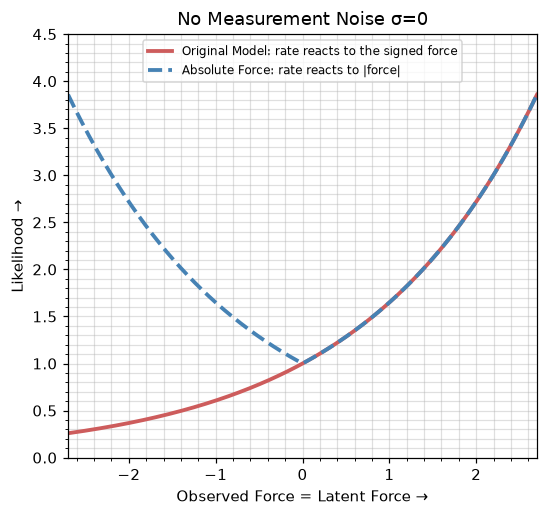

In [5]:
def noise_panel(title):
    orig, absf, xlabel = curves[title]
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot(Fs, orig, color="indianred", lw=2.5, label="Original Model: rate reacts to the signed force")
    ax.plot(Fs, absf, "--", color="steelblue", lw=2.5, label="Absolute Force: rate reacts to |force|")
    ax.set(title=title, xlabel=xlabel + " →", ylabel="Likelihood →", ylim=(0, 4.5), xlim=(Fs[0], Fs[-1]))
    ax.minorticks_on(); ax.grid(which="both", alpha=0.4)
    ax.legend(loc="upper center", fontsize=8)
    return fig

noise_panel("No Measurement Noise σ=0"); savefig("fig14a_noise_likelihood_sigma0");

### Figure 14 (p. 46), right: measurement noise σ = 1

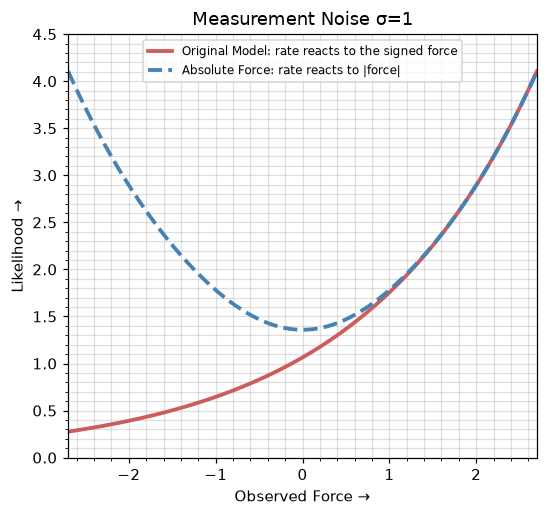

In [6]:
noise_panel("Measurement Noise σ=1"); savefig("fig14b_noise_likelihood_sigma1");

**Figure 14 (p. 46).** Likelihood of the measured force. Left: without noise, a negative force in the original model
implies a rate below $r_{u,0}$; if a negative force merely indicates a change of direction, only the absolute value
should enter. Right: with noise, the original model is barely affected, while the absolute-force model changes
significantly — low forces can now be explained by positive *or* negative latent forces.

## 3.5 Optimizing experimental design

The driving velocity $v$ determines for which regime data is collected: slow driving probes the base rate $r_{u,0}$,
fast driving the sensitivity $x_u$. Bayesian Optimal Experimental Design chooses $v$ by maximising an expected
utility $EU(v)=\int\mathrm dT^*\,p(T^*\mid T_\text{old},v)\,U(T^*)$, e.g. the information gained about the bond
parameters (the KL divergence from the current to the updated posterior).

Figure 15 illustrates how the choice of $v$ shapes the posterior: for ten velocities $v$ (log-spaced between $10^{-1.5}$
and $1$) we simulate 300 trajectories each and compute the posterior of each set. For each set the 90 % highest-density
region of the (slightly smoothed, `gaussian_filter` with width 1) posterior is drawn in the colour of its velocity.
The black contours belong to the combined posterior of all sets (the product of all likelihoods), once tempered by
the number of sets (outer contour) and once untempered (inner contour).

In [7]:
velocities = np.logspace(-1.5, 0, 10)
sets = [(v, bonds.simulate_trajectories(force, RU0_GT, XU_GT, v=v, dt=DT, rng=rng, n=300)[0]) for v in velocities]

ru0_grid = np.linspace(0, 2.2 * RU0_GT, 100)
xu_grid = np.linspace(0, 2.2 * XU_GT, 100)
logps = [bonds.log_likelihood_grid(trajs, ru0_grid, xu_grid, DT) for _, trajs in sets]

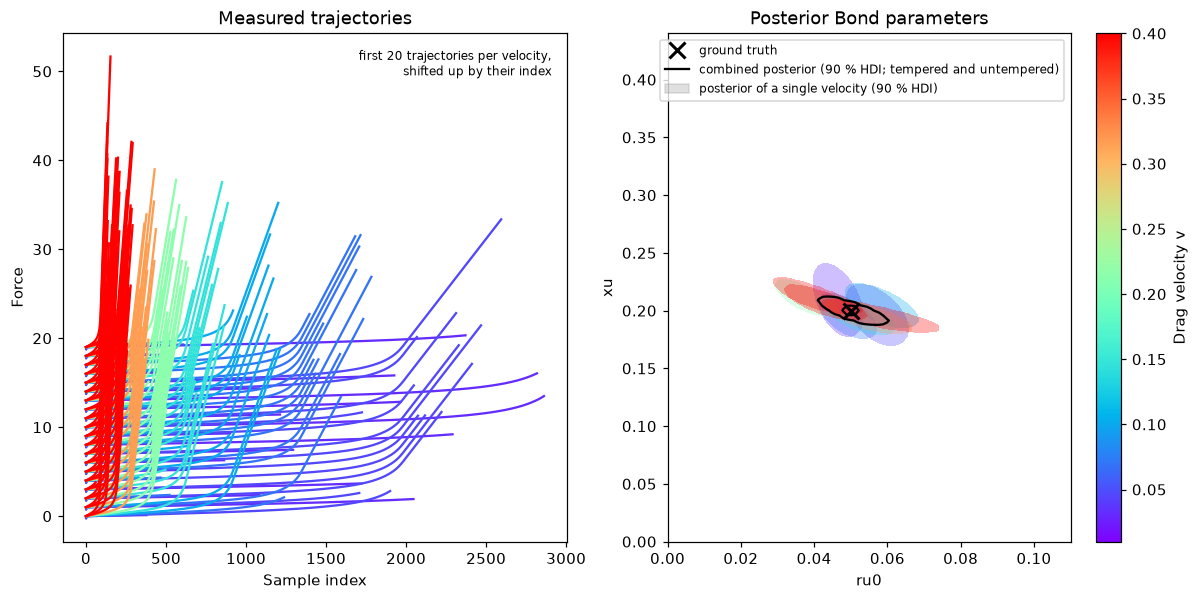

In [8]:
vnorm = mpl.colors.Normalize(vmin=0.01, vmax=0.4)
vcol = mpl.cm.ScalarMappable(norm=vnorm, cmap="rainbow")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6))
for v, trajs in sets:
    for i, Fi in enumerate(trajs[:20]):
        a1.plot(Fi + i, color=vcol.to_rgba(v))
a1.set(title="Measured trajectories", xlabel="Sample index", ylabel="Force")
a1.text(0.97, 0.97, "first 20 trajectories per velocity,\nshifted up by their index", transform=a1.transAxes,
        ha="right", va="top", fontsize=8)

ext = (ru0_grid[0], ru0_grid[-1], xu_grid[0], xu_grid[-1])
for (v, _), logp in zip(sets, logps):
    P = np.exp(logp - logp.max())
    level = bonds.hdi_threshold(P, 0.90)
    a2.contourf(gaussian_filter(P, 1), origin="lower", extent=ext, levels=[level, 1], alpha=0.3, colors=[vcol.to_rgba(v)])
total = sum(logps)
for logp in (total / len(logps), total):
    P = np.exp(logp - logp.max())
    a2.contour(P, origin="lower", extent=ext, levels=[bonds.hdi_threshold(P, 0.90)], colors="k")
a2.plot([RU0_GT], [XU_GT], "kx", markersize=10, markeredgewidth=2, label="ground truth")
a2.plot([], [], "k-", label="combined posterior (90 % HDI; tempered and untempered)")
a2.fill_between([], [], color="0.6", alpha=0.3, label="posterior of a single velocity (90 % HDI)")
a2.set(title="Posterior Bond parameters", xlabel="ru0", ylabel="xu", xlim=ext[:2], ylim=ext[2:])
a2.legend(loc="upper right", fontsize=8)
fig.colorbar(vcol, ax=a2, label="Drag velocity v")
savefig("fig15_v_entropy_comparison");

**Figure 15 (p. 49).** Left: trajectories at different $v$ — slow driving gives long lifetimes and low breaking forces,
fast driving raises the force quickly. Right: posteriors of the bond parameters as a function of $v$. Small $v$ constrain
$r_{u,0}$, large $v$ constrain $x_u$. Each observation acts as a filter on the prior; the design optimisation predicts the
choice of $v$ that cuts away as much of the parameter space as possible.

**Expected utility (Figure 16).** Starting from the flat prior on the grid $r_{u,0}\in[r_{u,0}^\text{GT}/4,\,2r_{u,0}^\text{GT}]$,
$x_u\in[x_u^\text{GT}/4,\,2x_u^\text{GT}]$ (100 × 100 points), we simulate 100 000 test trajectories $T^*$ with velocities
$v\sim\mathcal U(0.1, 2)$. The utility of a test trajectory is its log-likelihood summed over the prior grid — the
more parameter space a trajectory excludes, the larger its magnitude. Averaging over test trajectories in 15 velocity
bins gives the expected utility $EU(v)$, shown relative to its maximum.

*Code:* `bonds.utility_per_trajectory(trajs, ru0_grid, xu_grid, dt)` — a numba kernel, parallel over trajectories.
Simulation and evaluation take several minutes and are cached in `results/`.

[cache] computing fig16_expected_utility ...


optimal planned velocity: v_opt ≈ 0.92


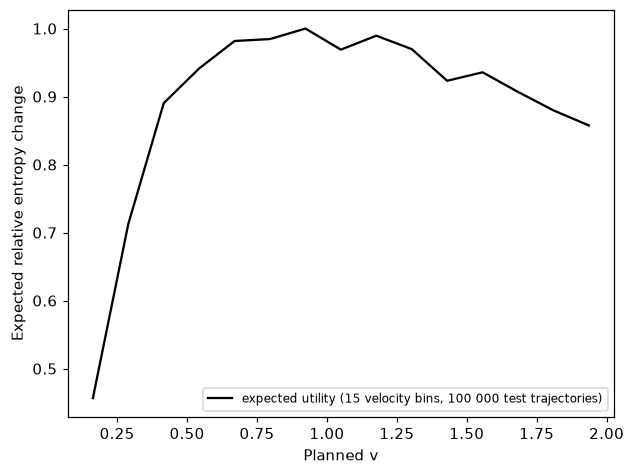

In [9]:
def expected_utility():
    trajs, v = bonds.simulate_trajectories(force, RU0_GT, XU_GT, v=lambda r: r.uniform(0.1, 2), dt=DT, rng=rng, n=100_000)
    u = bonds.utility_per_trajectory(trajs, np.linspace(RU0_GT / 4, 2 * RU0_GT, 100),
                                     np.linspace(XU_GT / 4, 2 * XU_GT, 100), DT)
    return {"v": v, "utility": u}

res = lt.cached("fig16_expected_utility", expected_utility)
stat = binned_statistic(res["v"], res["utility"], bins=15)
v_centers = (stat.bin_edges[:-1] + stat.bin_edges[1:]) / 2
eu = stat.statistic / stat.statistic.min()        # utilities are negative: the largest magnitude maps to 1

plt.figure()
plt.plot(v_centers, eu, "k", label="expected utility (15 velocity bins, 100 000 test trajectories)")
plt.xlabel("Planned v")
plt.ylabel("Expected relative entropy change")
plt.legend(loc="lower right", fontsize=8)
v_opt = v_centers[np.argmax(eu)]
print(f"optimal planned velocity: v_opt ≈ {v_opt:.2f}")
savefig("fig16_planned_v_optimal");

**Figure 16 (p. 50).** Expected information gain as a function of the design parameter $v$, starting from the flat prior.
The peak is the ideal choice for the first run of the experiment; after it, the new evidence is assimilated and the
optimisation is repeated.